# 4 dimensional system - B, W, H, L 

In [ ]:
using DifferentialEquations
using Plots 
using LinearAlgebra
using Printf
using Base.Threads



function RHS!(du, u, p, t)
    #u = [B, W, H, L]
    B, W, H, L = u
    
    #parameters 
    lambda0, E, K_B, M_B, alpha, kappa, beta, P, N, R, GamW, M_H, GamH, K_H, eta, mu, L0 = p
    
    f_L = (L + L0)/(L + kappa + L0)
    sat = 1.0/(beta + B)
    growth = lambda0 * W * B * (1 + (E * B))^2 * (1.0 - (B/K_B))
    evaporation = N * W/(1.0 + (R * B/K_B))
    uptake = GamW * W * B * (1.0 + (E * B))^2
    consumption = alpha * B * H * f_L * sat 
    
    du[1] = growth - (M_B * B) - consumption
    du[2] = P - evaporation - uptake
    du[3] = (-M_H * H) + (GamH * consumption * (1.0 - (H/K_H)))
    du[4] = (eta * B * H) - (mu * L)
    
    return nothing 
end 
#############parameters 
lambda0 = 0.6
E = 10.0
K_B = 10.0
M_B = 10.0
alpha = 43
kappa = 0.01
beta = 0.1
P = 95.0
N = 20.0
R = 0.01
GamW = 10.0
M_H = 3.0
GamH = 0.2
K_H = 0.1
eta = 0.8
mu = 1.1
L0 = 0.006

p = (lambda0, E, K_B, M_B, alpha, kappa, beta, P, N, R, GamW, M_H, GamH, K_H, eta, mu, L0)

#initial condition
u0 = [1.0, 0.7311060728971344, 0.05, 0.025]

tmin = 0.0
tmax = 60
tspan = (tmin, tmax)

prob = ODEProblem(RHS!, u0, tspan, p)

#5th order Runge-Kutta
sol = solve(prob, Tsit5(); dt=1e-5, adaptive=true, reltol=1e-12, abstol=1e-13)
T = sol.t
B = [u[1] for u in sol.u]
W = [u[2] for u in sol.u]
H = [u[3] for u in sol.u]
L = [u[4] for u in sol.u]

plt = plot(T, B; lw = 2, label = "B(t)", color = "green")
plot!(plt, T, W; lw = 2, label = "W(t)", color = "blue")
plot!(plt, T, H; lw = 2, label = "H(t)", color = "black")
plot!(plt, T, L; lw = 2, label = "L(t)", color = "red")

xlabel!(plt, "time")
ylabel!(plt, "[B, W, H, L]")
display(plt)
sol.u[end]

# 5 Dimensional system - B, W, H, L, P

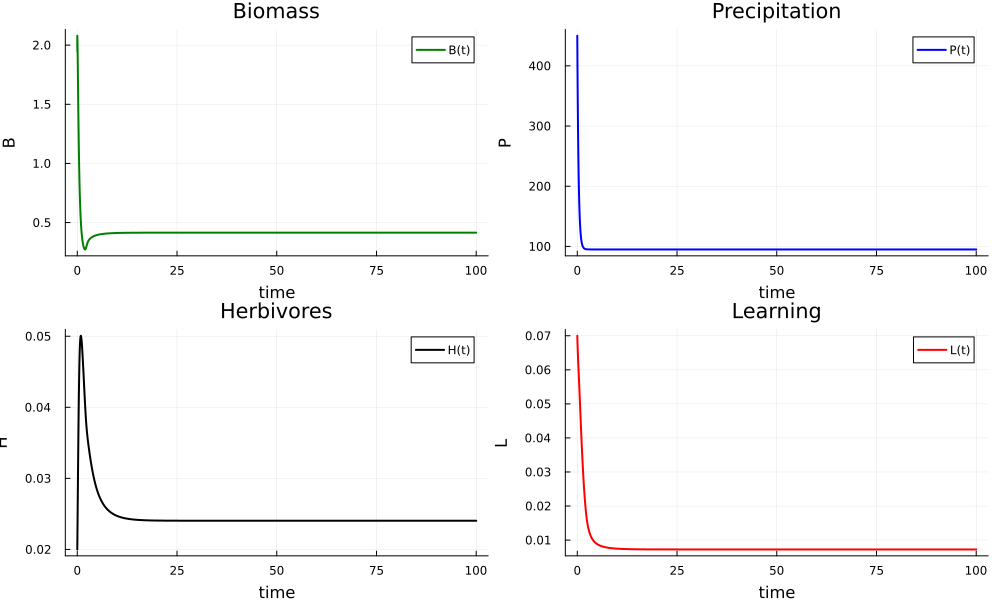

In [4]:
using DifferentialEquations
using Plots
function RHS!(du, u, p, t)
    #u = [B, W, H, L]
    B, W, H, L, P = u    
    #parameters 
    lambda0, E, K_B, M_B, alpha, kappa, beta, r, N, R, GamW, M_H, GamH, K_H, eta, mu, L0 = p    
    f_L = (L + L0)/(L + kappa + L0)
    sat = 1.0/(beta + B)
    growth = lambda0 * W * B * (1 + (E * B))^2 * (1.0 - (B/K_B))
    evaporation = N * W/(1.0 + (R * B/K_B))
    uptake = GamW * W * B * (1.0 + (E * B))^2
    consumption = alpha * B * H * f_L * sat    
    du[1] = growth - (M_B * B) - consumption
    du[2] = P - evaporation - uptake
    du[3] = (-M_H * H) + (GamH * consumption * (1.0 - (H/K_H)))
    du[4] = (eta * B * H) - (mu * L)
    du[5] = -r * (P - 95.0)    
    #du[5] = -r
    return nothing 
end 
#############parameters 
lambda0 = 0.6
E = 10.0
K_B = 10.0
M_B = 10.0
alpha = 43
kappa = 0.01
beta = 0.1
r = 3.1
N = 20.0
R = 0.01
GamW = 10.0
M_H = 3.0
GamH = 0.2
K_H = 0.1
eta = 0.8
mu = 1.1
L0 = 0.006

p = (lambda0, E, K_B, M_B, alpha, kappa, beta, r, N, R, GamW, M_H, GamH, K_H, eta, mu, L0)

#initial condition
Bini = 1.949877
Wini = 2.7472462764224987 
Hini = 0.02
Lini = 0.07
Pini = 449.949712
u0 = [Bini, Wini, Hini, Lini, Pini]
tmin = 0.0
tmax = 100
tspan = (tmin, tmax)

prob = ODEProblem(RHS!, u0, tspan, p)
sol = solve(prob, Tsit5(); dt=1e-5, adaptive=true, reltol=1e-12, abstol=1e-13)

T = sol.t
B = [u[1] for u in sol.u]
W = [u[2] for u in sol.u]
H = [u[3] for u in sol.u]
L = [u[4] for u in sol.u]
P = [u[5] for u in sol.u]
plt1 = plot(T, B;
    lw = 2,
    label = "B(t)",
    color = "green",
    xlabel = "time",
    ylabel = "B",
    title = "Biomass"
)
plt2 = plot(T, P;
    lw = 2,
    label = "P(t)",
    color = "blue",
    xlabel = "time",
    ylabel = "P",
    title = "Precipitation"
)
plt3 = plot(T, H;
    lw = 2,
    label = "H(t)",
    color = "black",
    xlabel = "time",
    ylabel = "H",
    title = "Herbivores"
)
plt4 = plot(T, L;
    lw = 2,
    label = "L(t)",
    color = "red",
    xlabel = "time",
    ylabel = "L",
    title = "Learning"
)
plt = plot(plt1, plt2, plt3, plt4; layout = (2, 2), size = (1000, 600))
display(plt)
#----------------- end -------------------------- 
